In [11]:

import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [12]:
rdata_1 = pd.read_parquet(f"../.temp\\data\\experiment_results\\random\\results_500000.parquet").assign(budget=500000)
rdata_2 = pd.read_parquet(f"../.temp\\data\\experiment_results\\random\\results_1000000.parquet").assign(budget=1000000)
rdata_3 = pd.read_parquet(f"../.temp\\data\\experiment_results\\random\\results_10000000.parquet").assign(budget=10000000)
rdata = pd.concat([
    rdata_1,
    rdata_2,
    rdata_3
]).assign(experiment = 'Random')

In [13]:
ldata_1 = pd.read_parquet(f"../.temp\\data\\experiment_results\\dqn\\loss_dqn_budget_500000.parquet").assign(budget=500000)
ldata_2 = pd.read_parquet(f"../.temp\\data\\experiment_results\\dqn\\loss_dqn_budget_1000000.parquet").assign(budget=1000000)
ldata_3 = pd.read_parquet(f"../.temp\\data\\experiment_results\\dqn\\loss_dqn_budget_10000000.parquet").assign(budget=10000000)
ldata = pd.concat([
    ldata_1,
    ldata_2,
    ldata_3
]).assign(experiment = 'DQN')

In [15]:
data_1 = pd.read_parquet(f"../.temp\\data\\experiment_results\\dqn\\insurenv_results_500000.parquet").assign(budget=500000)
data_2 = pd.read_parquet(f"../.temp\\data\\experiment_results\\dqn\\insurenv_results_1000000.parquet").assign(budget=1000000)
data_3 = pd.read_parquet(f"../.temp\\data\\experiment_results\\dqn\\insurenv_results_10000000.parquet").assign(budget=10000000)
data = pd.concat([
    data_1,
    data_2,
    data_3
]).assign(experiment = 'DQN')

In [17]:
full_data = pd.concat([data,rdata], axis=0).reset_index(drop = True)

In [18]:
px.box(full_data,  y = 'cum_rewards', facet_row = 'budget', color='experiment', height=900)

In [19]:
px.box()

In [20]:
full_data.pivot_table(index = ["experiment", "initial_budget", "episodes"], columns = 'decision', values ='wc', aggfunc = 'count')

decision                            0.0  1.0
experiment initial_budget episodes          
DQN        500000         1           7    6
                          2           6    5
                          3          10    8
                          4          10    6
           1000000        1           8    5
                          2          14   13
                          3          14   17
           10000000       1          25   25
                          2          24   26
                          3          17   33
                          4          18   32
Random     500000         0          10    8
                          1          13    8
                          2          11   10
                          3           9    6
                          4           6    4
           1000000        0           5    8
                          1          10    8
                          2          14   16
                          3           7   10
                          4          19   10
           10000000       0          30   20
                          1          27   23
                          2          20   30
                          3          23   27
                          4          21   29

In [17]:
import scipy.stats as stats
import numpy as np

# Create the pivot table
pivot_table = full_data.pivot_table(
    index=["initial_budget", "experiment"],  # Rows to group by
    columns=["decision"],  # Columns to group by
    values="wc",  # The values to aggregate
    aggfunc="sum",  # You can change this depending on what you want to compute (sum, mean, etc.)
    fill_value=0  # In case there are missing values, this will replace them with 0
)

# Calculate percentage along columns (decision)
percentage_table = pivot_table.div(pivot_table.sum(axis=1), axis=0) * 100

# Display the percentage table
percentage_table


decision                         0.0        1.0
initial_budget experiment                      
500000         DQN         58.539216  41.460784
               Random      61.358088  38.641912
1000000        DQN         48.250684  51.749316
               Random      48.858888  51.141112
10000000       DQN         42.484850  57.515150
               Random      51.824756  48.175244

In [18]:
import pandas as pd

# Create the pivot table
pivot_table = full_data.pivot_table(
    index=["initial_budget", "experiment"],  # Rows to group by
    columns=["decision"],  # Columns to group by
    values="wc",  # The values to aggregate (assuming 'wc' is some weight/count metric)
    aggfunc="sum",  # Aggregating the values by summing them
    fill_value=0  # Filling missing values with 0
)

# Calculate percentage along columns (decision)
percentage_table = pivot_table.div(pivot_table.sum(axis=1), axis=0) * 100

# Flatten the multi-index for better readability
percentage_table.columns = [f'{col}' for col in percentage_table.columns]

# Optionally, reset the index to have 'initial_budget' and 'experiment' as columns
percentage_table = percentage_table.reset_index()
percentage_table


,initial_budget,experiment,0.0,1.0
0,500000,DQN,58.539216,41.460784
1,500000,Random,61.358088,38.641912
2,1000000,DQN,48.250684,51.749316
3,1000000,Random,48.858888,51.141112
4,10000000,DQN,42.484850,57.515150
5,10000000,Random,51.824756,48.175244


In [19]:
full_data.groupby(["experiment", "initial_budget"])['steps'].describe()

count       mean        std  min    25%   50%  \
experiment initial_budget                                                  
DQN        500000           58.0   8.000000   4.622599  1.0   4.00   8.0   
           1000000          71.0  13.591549   8.492984  1.0   6.50  12.0   
           10000000        200.0  25.500000  14.467083  1.0  13.00  25.5   
Random     500000           75.0  10.040000   5.707842  1.0   5.00  10.0   
           1000000          78.0  11.282051   7.420396  1.0   5.25  10.0   
           10000000        200.0  25.500000  14.467083  1.0  13.00  25.5   

                             75%   max  
experiment initial_budget               
DQN        500000          11.00  18.0  
           1000000         20.50  31.0  
           10000000        38.00  50.0  
Random     500000          14.50  21.0  
           1000000         15.75  30.0  
           10000000        38.00  50.0

In [21]:
import os
# Ensure the directory exists
output_dir = '../.temp/plots'
os.makedirs(output_dir, exist_ok=True)
data = full_data
# Create and save the plot
g = sns.FacetGrid(data, col='initial_budget', row='experiment', margin_titles=True, sharex=False)
g.map(plt.hist, 'steps', bins=30, edgecolor='black')
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')

# Save the figure
plot_path = os.path.join(output_dir, 'episode_lengths_by_experiment_and_budget.png')
g.savefig(plot_path)
plt.close(g.fig)

print(f"Plot saved to {plot_path}")

Plot saved to ../.temp/plots\episode_lengths_by_experiment_and_budget.png


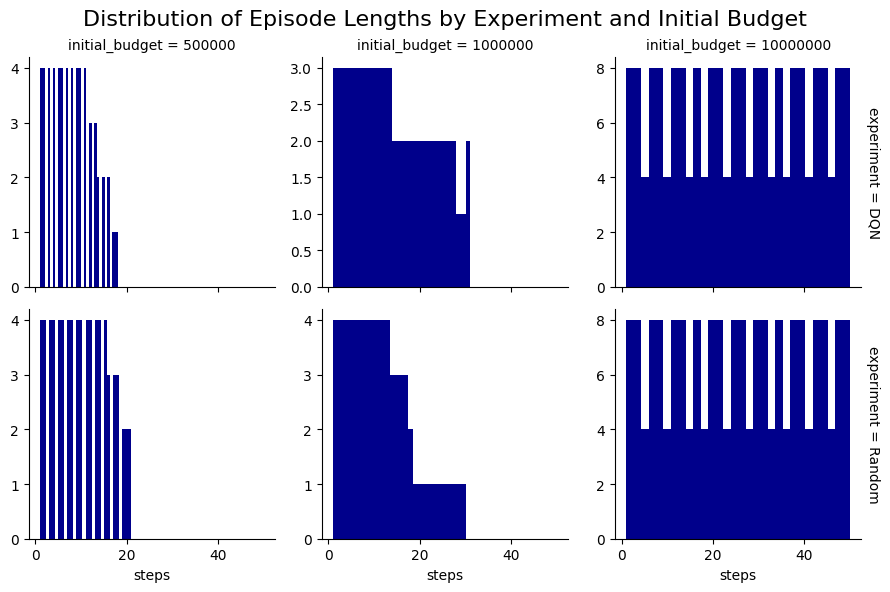

In [102]:

# Assuming `full_data` has columns: 'initial_budget', 'experiment', 'steps'
# First, ensure the correct data types
full_data['initial_budget'] = full_data['initial_budget'].astype(int)
full_data['steps'] = full_data['steps'].astype(int)

# Create the grid of plots using seaborn's FacetGrid
g = sns.FacetGrid(full_data, row="experiment", col="initial_budget", margin_titles=True, sharey=False)

# Map the histograms onto the grid
g.map(plt.hist, "steps", bins=30, color="darkblue")

# Set the axis labels and title
g.set_axis_labels("steps", "")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("Distribution of Episode Lengths by Experiment and Initial Budget", fontsize=16)

# Show the plot
plt.show()


In [24]:
# Assuming 'data' is your DataFrame
# Perform the statistical analysis
data = full_data
grouped_stats = data.groupby(['experiment', 'initial_budget'])['steps'].agg(['mean', 'median', 'std', 'min', 'max', 'count'])

# To get more insights, you might want to calculate the interquartile range (IQR)
def calculate_iqr(series):
    return series.quantile(0.75) - series.quantile(0.25)

# Adding IQR to the grouped statistics
grouped_stats['iqr'] = data.groupby(['experiment', 'initial_budget'])['steps'].apply(calculate_iqr)

# Reset index to make 'experiment' and 'initial_budget' as columns again
grouped_stats = grouped_stats.reset_index()

# Display the statistics
print(grouped_stats)

# Optionally, save this to a CSV file
output_stats_path = 'experiment_results/stats/episode_length_stats.csv'
os.makedirs('experiment_results/stats', exist_ok=True)
grouped_stats.to_csv(output_stats_path, index=False)

print(f"Statistical analysis results saved to {output_stats_path}")

  experiment  initial_budget       mean  median        std  min  max  count  \
0        DQN          500000   8.000000     8.0   4.622599    1   18     58   
1        DQN         1000000  13.591549    12.0   8.492984    1   31     71   
2        DQN        10000000  25.500000    25.5  14.467083    1   50    200   
3     Random          500000  10.040000    10.0   5.707842    1   21     75   
4     Random         1000000  11.282051    10.0   7.420396    1   30     78   
5     Random        10000000  25.500000    25.5  14.467083    1   50    200   

    iqr  
0   7.0  
1  14.0  
2  25.0  
3   9.5  
4  10.5  
5  25.0  
Statistical analysis results saved to experiment_results/stats/episode_length_stats.csv


In [71]:
full_data.groupby(["experiment", "initial_budget", "episodes"])['steps'].describe()

count   mean        std  min    25%  \
experiment initial_budget episodes                                        
DQN        500000         1          13.0    7.0   3.894440  1.0   4.00   
                          2          11.0    6.0   3.316625  1.0   3.50   
                          3          18.0    9.5   5.338539  1.0   5.25   
                          4          16.0    8.5   4.760952  1.0   4.75   
           1000000        1          13.0    7.0   3.894440  1.0   4.00   
                          2          27.0   14.0   7.937254  1.0   7.50   
                          3          31.0   16.0   9.092121  1.0   8.50   
           10000000       1          50.0   25.5  14.577380  1.0  13.25   
                          2          50.0   25.5  14.577380  1.0  13.25   
                          3          50.0   25.5  14.577380  1.0  13.25   
                          4          50.0   25.5  14.577380  1.0  13.25   
Random     500000         0          25.0   13.0   7.359801  1.0   7.00   
                          1          11.0    6.0   3.316625  1.0   3.50   
                          2          16.0    8.5   4.760952  1.0   4.75   
                          3          17.0    9.0   5.049752  1.0   5.00   
                          4          23.0   12.0   6.782330  1.0   6.50   
           1000000        0          23.0   12.0   6.782330  1.0   6.50   
                          1          33.0   17.0   9.669540  1.0   9.00   
                          2          35.0   18.0  10.246951  1.0   9.50   
                          3          33.0   17.0   9.669540  1.0   9.00   
                          4          28.0   14.5   8.225975  1.0   7.75   
           10000000       0         244.0  122.5  70.580923  1.0  61.75   
                          1         274.0  137.5  79.241193  1.0  69.25   
                          2         231.0  116.0  66.828138  1.0  58.50   
                          3         250.0  125.5  72.312977  1.0  63.25   
                          4         226.0  113.5  65.384759  1.0  57.25   

                                      50%     75%    max  
experiment initial_budget episodes                        
DQN        500000         1           7.0   10.00   13.0  
                          2           6.0    8.50   11.0  
                          3           9.5   13.75   18.0  
                          4           8.5   12.25   16.0  
           1000000        1           7.0   10.00   13.0  
                          2          14.0   20.50   27.0  
                          3          16.0   23.50   31.0  
           10000000       1          25.5   37.75   50.0  
                          2          25.5   37.75   50.0  
                          3          25.5   37.75   50.0  
                          4          25.5   37.75   50.0  
Random     500000         0          13.0   19.00   25.0  
                          1           6.0    8.50   11.0  
                          2           8.5   12.25   16.0  
                          3           9.0   13.00   17.0  
                          4          12.0   17.50   23.0  
           1000000        0          12.0   17.50   23.0  
                          1          17.0   25.00   33.0  
                          2          18.0   26.50   35.0  
                          3          17.0   25.00   33.0  
                          4          14.5   21.25   28.0  
           10000000       0         122.5  183.25  244.0  
                          1         137.5  205.75  274.0  
                          2         116.0  173.50  231.0  
                          3         125.5  187.75  250.0  
                          4         113.5  169.75  226.0

In [42]:
full_data.groupby(["initial_budget", "episodes"])['decision'].describe()

count      mean       std  min  25%  50%  75%  max
initial_budget episodes                                                    
500000         1          13.0  0.461538  0.518875  0.0  0.0  0.0  1.0  1.0
               2          11.0  0.454545  0.522233  0.0  0.0  0.0  1.0  1.0
               3          18.0  0.444444  0.511310  0.0  0.0  0.0  1.0  1.0
               4          16.0  0.375000  0.500000  0.0  0.0  0.0  1.0  1.0
1000000        1          13.0  0.384615  0.506370  0.0  0.0  0.0  1.0  1.0
               2          27.0  0.481481  0.509175  0.0  0.0  0.0  1.0  1.0
               3          31.0  0.548387  0.505879  0.0  0.0  1.0  1.0  1.0
10000000       1          50.0  0.500000  0.505076  0.0  0.0  0.5  1.0  1.0
               2          50.0  0.520000  0.504672  0.0  0.0  1.0  1.0  1.0
               3          50.0  0.660000  0.478518  0.0  0.0  1.0  1.0  1.0
               4          50.0  0.640000  0.484873  0.0  0.0  1.0  1.0  1.0

In [28]:
import pandas as pd
import plotly.express as px

# Assuming 'full_data' has the following columns: 'experiment', 'initial_budget', 'episode', 'steps', and 'rewards'
# First, calculate cumulative rewards for each episode grouped by 'experiment' and 'initial_budget'
full_data['cumulative_rewards'] = full_data.groupby(['experiment', 'initial_budget', 'episodes'])['rewards'].cumsum()

# Create the line plot using Plotly with facet for 'experiment' and color for 'initial_budget'
fig = px.line(
    full_data,
    x='steps',  # Steps as the x-axis
    y='cumulative_rewards',  # Cumulative rewards on the y-axis
    color='initial_budget',  # Color lines by initial budget
    facet_row='experiment',  # Facet by experiment type
    line_group='episodes',  # Each episode gets its own line
    title='Cumulative Rewards by Experiment, Initial Budget, and Episode',
    labels={'steps': 'Steps', 'cumulative_rewards': 'Cumulative Rewards'}
)

# Update layout for better presentation
fig.update_layout(height=800, width=1000, title_x=0.5)

# Show the figure
fig.show()


In [30]:
import pandas as pd
import plotly.express as px

# Assuming 'full_data' has the necessary columns
# Apply a rolling average to smooth the cumulative rewards, with a window size of 5 steps
full_data['smoothed_rewards'] = full_data.groupby(['experiment', 'initial_budget', 'episodes'])['rewards'].apply(lambda x: x.rolling(window=5, min_periods=1).mean())

# Recalculate the cumulative rewards after smoothing
full_data['cumulative_rewards'] = full_data.groupby(['experiment', 'initial_budget', 'episodes'])['smoothed_rewards'].cumsum()

# Create the line plot with separate subplots for each 'initial_budget' and experiment
fig = px.line(
    full_data,
    x='steps',
    y='cumulative_rewards',
    color='experiment',  # Color lines by experiment (DQN, Random)
    facet_col='initial_budget',  # Facet by initial budget, creating separate plots for each budget level
    line_group='episodes',  # Each episode gets its own line
    title='Smoothed Cumulative Rewards by Experiment and Initial Budget',
    labels={'steps': 'Steps', 'cumulative_rewards': 'Cumulative Rewards'}
)

# Update layout for better presentation
fig.update_layout(
    height=600, 
    width=1000, 
    title_x=0.5,
    legend_title_text='Experiment',
    legend=dict(x=1.05, y=1)  # Move the legend outside the plot
)

# Show the plot
fig.show()


TypeError: incompatible index of inserted column with frame index